# 81 · Swap the diffusion head for flow matching: same backbone, same data; success vs network evaluations

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import DiffusionPolicy, FlowPolicy, train_policy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
H = 16

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
flow = FlowPolicy(horizon=H)
if os.path.exists("checkpoints/flow.pt"):
    flow.load_state_dict(torch.load("checkpoints/flow.pt", map_location=device)); flow.to(device)
else:
    t0 = time.time(); losses = train_policy(flow, ds, epochs=60, lr=1e-4, device=device, log_every=5)
    torch.save(flow.state_dict(), "checkpoints/flow.pt"); print(f"trained in {time.time() - t0:.0f}s")
diff = DiffusionPolicy(horizon=H)
diff.load_state_dict(torch.load("checkpoints/diffusion.pt", map_location=device)); diff.to(device)

DiffusionPolicy(
  (obs): ObsEncoder(
    (backbone): ImageEncoder(
      (trunk): Sequential(
        (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (1): GroupNorm(4, 64, eps=1e-05, affine=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
        (4): Sequential(
          (0): BasicBlock(
            (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn1): GroupNorm(4, 64, eps=1e-05, affine=True)
            (relu): ReLU(inplace=True)
            (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn2): GroupNorm(4, 64, eps=1e-05, affine=True)
          )
          (1): BasicBlock(
            (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn1): GroupNorm(4, 64, eps=1e-05, affine=True)
            (relu): ReLU(inplace=T

In [3]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
nfes = [1, 2, 4, 10]
table = {}
for name, net in [("diffusion (DDIM)", diff), ("flow (Euler)", flow)]:
    table[name] = []
    for k in nfes:
        t0 = time.time()
        r = evaluate(env, ChunkPolicy(net, ds, env, device, execute=8, nfe=k), n_episodes=40, seed=50_000)
        table[name].append((r["success"], *r["ci"], time.time() - t0))
        print(f"{name:17s} NFE={k:2d}: success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]  eval time {time.time() - t0:.0f}s")

diffusion (DDIM)  NFE= 1: success 0.00 CI [-0.00, 0.09]  eval time 99s


diffusion (DDIM)  NFE= 2: success 0.00 CI [-0.00, 0.09]  eval time 111s


diffusion (DDIM)  NFE= 4: success 0.72 CI [0.57, 0.84]  eval time 55s


diffusion (DDIM)  NFE=10: success 1.00 CI [0.91, 1.00]  eval time 38s


flow (Euler)      NFE= 1: success 0.95 CI [0.83, 0.99]  eval time 22s


flow (Euler)      NFE= 2: success 0.97 CI [0.87, 1.00]  eval time 25s


flow (Euler)      NFE= 4: success 1.00 CI [0.91, 1.00]  eval time 18s


flow (Euler)      NFE=10: success 0.97 CI [0.87, 1.00]  eval time 21s


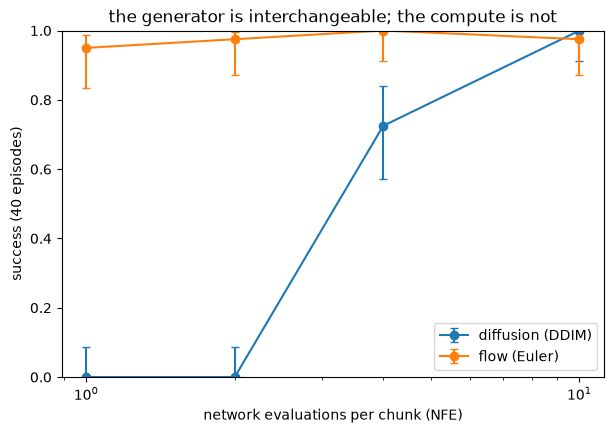

In [4]:
plt.figure(figsize=(7, 4.5))
for name, rows in table.items():
    rows = np.array(rows)
    plt.errorbar(nfes, rows[:, 0], yerr=[rows[:, 0] - rows[:, 1], rows[:, 2] - rows[:, 0]], marker="o", capsize=3, label=name)
plt.xscale("log"); plt.xlabel("network evaluations per chunk (NFE)"); plt.ylabel("success (40 episodes)"); plt.ylim(0, 1); plt.legend()
plt.title("the generator is interchangeable; the compute is not"); plt.show()

In [5]:
b = {k: v[None].to(device) for k, v in ds[0].items() if k != "pad_mask"}
for name, net in [("diffusion", diff), ("flow", flow)]:
    for k in [1, 10]:
        torch.cuda.synchronize() if device == "cuda" else None
        t0 = time.perf_counter()
        for _ in range(20):
            net.sample(b, nfe=k)
        torch.cuda.synchronize() if device == "cuda" else None
        print(f"{name:9s} NFE={k:2d}: {(time.perf_counter() - t0) / 20 * 1000:6.1f} ms per chunk")

diffusion NFE= 1:   19.5 ms per chunk


diffusion NFE=10:   74.9 ms per chunk


flow      NFE= 1:   14.8 ms per chunk


flow      NFE=10:   30.8 ms per chunk


### Watch it: 10 denoising steps vs 1 flow step
Same episode. Flow matching with a single network call per chunk against DDIM with ten.

In [6]:
from vlacourse import showcase as sc
sc.compare(env, {"Diffusion, DDIM 10 steps": ChunkPolicy(diff, ds, env, device, execute=8, nfe=10),
                  "Flow matching, 1 Euler step": ChunkPolicy(flow, ds, env, device, execute=8, nfe=1)}, seed=50_001, title="81 diffusion vs flow")

81 diffusion vs flow: Diffusion, DDIM 10 steps: success | Flow matching, 1 Euler step: success


[True, True]